# Hoja de trabajo HT05

In [16]:
import numpy as np
from scipy import stats
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Parte 1: Exploración y Correlación

In [17]:
#carga de datos
df = sns.load_dataset('tips')
df.head(5)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [18]:
#Matriz de correlación
matriz_corr = df[['total_bill', 'tip', 'size']].corr(method='pearson')
print("Matriz de Correlación de Pearson:")
display(matriz_corr)

Matriz de Correlación de Pearson:


,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


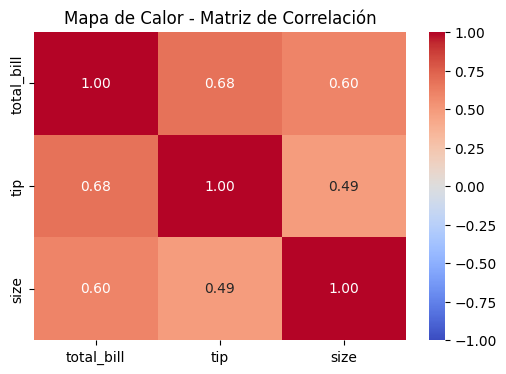

In [19]:
#Mapa de calor
plt.figure(figsize=(6, 4))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Mapa de Calor - Matriz de Correlación")
plt.show()

**Pregunta de análisis: ¿Qué dirección (positiva/negativa) y qué fuerza (débil/moderada/fuerte) indica ese valor?**

El coeficiente de correlación de Pearson entre total_bill y tip se ubica en aproximadamente 0.68. Su dirección es positiva y de un color rojo oscuro , lo que significa que a medida que aumenta el monto de la cuenta a propina también tiende a aumentar. Basándonos en el rango indicado, tiene una correlación moderada, es decir que existe cierta dispersión. 

### Parte 2: Regresión Lineal Simple

In [20]:
X = df['total_bill'].values
Y = df['tip'].values

In [23]:
#Modelo de la relación
slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)
r_squared = r_value ** 2

#Métricas estadisticas
print(f"Pendiente (Slope / b1): {slope:.4f}")
print(f"Intersección (Intercept / b0): {intercept:.4f}")
print(f"Coeficiente de Correlación (r): {r_value:.4f}")
print(f"Coeficiente de Determinación (R²): {r_squared:.4f}")
print(f"Valor p (p-value): {p_value:.4e}")

Pendiente (Slope / b1): 0.1050
Intersección (Intercept / b0): 0.9203
Coeficiente de Correlación (r): 0.6757
Coeficiente de Determinación (R²): 0.4566
Valor p (p-value): 6.6925e-34


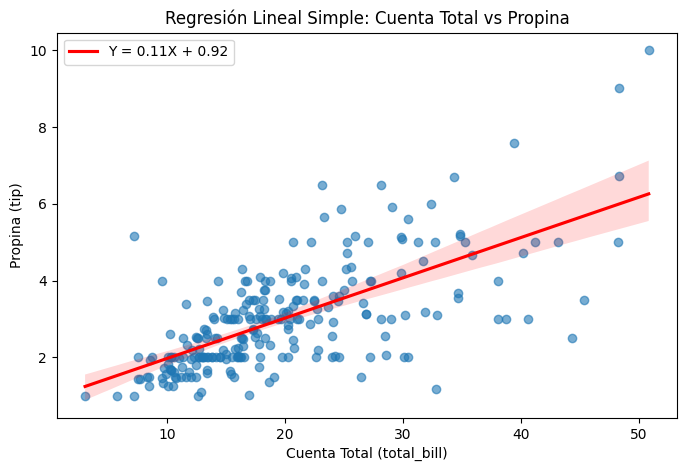

In [22]:
#Grafico de dispersión con recta 
plt.figure(figsize=(8, 5))
sns.regplot(x='total_bill', y='tip', data=df, 
            scatter_kws={'alpha':0.6}, 
            line_kws={'color':'red', 'label':f'Y = {slope:.2f}X + {intercept:.2f}'})
plt.title('Regresión Lineal Simple: Cuenta Total vs Propina')
plt.xlabel('Cuenta Total (total_bill)')
plt.ylabel('Propina (tip)')
plt.legend()
plt.show()

### Parte 3: Interpretación de Resultados

El resultado obtenido en la correlación, nos confirma positivamente que a mayor consumo en la cuenta, mayor tiende a ser la propina dejada por los clientes, mostrando una relación moderada. Sin embargo, esta relación no implica causalidad, no podemos afirmar que obligar a un cliente a consumir más cause directamente que auente su propina porcentual, sino que ambos comportamientos ocurren en conjunto dentro del restaurante. 

Además, se obtuvo una pendiente de 0.105, indicando que en promedio, por cada dólar adicional que se incrementa en la cuenta total, la propina esperada aumenta aproximadamente 10.5 centavos. Esto refleja la tendencia general de los comensales a propiciar basándose en el valor absoluto de consumo. 

Por último, el coeficiente de determinación de 0.46 nos indica que aproximadamente el 46% de la variabilidad total observada en las propinas queda explica por el monto de la cuenta. El 54% restante de la variación se debe a otros factores que el modelo no mide. Dentro de estos factores puede encontrarse el tamaño del grupo, la calidad del servicio, el día de la semana, etc. 

### Parte 4:  Pregunta de Reflexión Crítica

**¿Sería válido usar este modelo para predecir con exactitud la propina de una mesa específica un viernes por la noche? ¿Por qué?**

No sería válido, ya que para predecir con exactitud la propina de una mesa específica en un día y hora determinada, tendríamos que tomar en cuenta la gran cantidad de variables que pueden influir, por ejemplo: la excelente o pésima atención del mesero, el nivel de alcohol cosumido, si es una celebración especial o no, etc.

Este modelo de regresión lineal simple únicamente nos permite encontrar una tendencia promedio global del negocio. Sin embargo, falla al intentar adivinar el resultado exacto de un evento individual.